In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
phiusiil_phishing_url_website = fetch_ucirepo(id=967)

# data (as pandas dataframes)
X = phiusiil_phishing_url_website.data.features
y = phiusiil_phishing_url_website.data.targets

# metadata
print(phiusiil_phishing_url_website.metadata)

# variable information
print(phiusiil_phishing_url_website.variables)

{'uci_id': 967, 'name': 'PhiUSIIL Phishing URL (Website)', 'repository_url': 'https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/967/data.csv', 'abstract': 'PhiUSIIL Phishing URL Dataset is a substantial dataset comprising 134,850 legitimate and 100,945 phishing URLs. Most of the URLs we analyzed, while constructing the dataset, are the latest URLs. Features are extracted from the source code of the webpage and URL. Features such as CharContinuationRate, URLTitleMatchScore, URLCharProb, and TLDLegitimateProb are derived from existing features.', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 235795, 'num_features': 54, 'feature_types': ['Real', 'Categorical', 'Integer'], 'demographics': [], 'target_col': ['label'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2024, 'last_updated': 'Sun May 12 

label
1    134850
0    100945
Name: count, dtype: int64
label
1    57.189508
0    42.810492
Name: proportion, dtype: float64


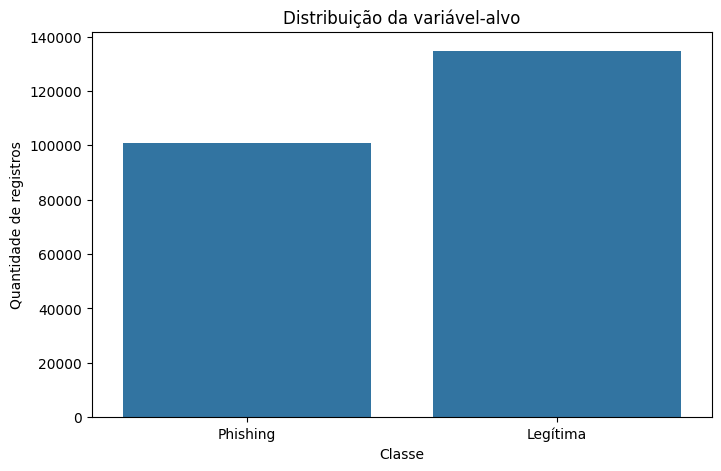

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



df = pd.concat([X, y], axis=1)

target = 'label'

# Frequência absoluta
print(df[target].value_counts())

# Frequência relativa
print(df[target].value_counts(normalize=True) * 100)

# Gráfico
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=target)

plt.title("Distribuição da variável-alvo")
plt.xlabel("Classe")
plt.ylabel("Quantidade de registros")
plt.xticks([0, 1], ["Phishing", "Legítima"])

plt.show()

In [ ]:

unique_values = df.nunique().sort_values()

print(unique_values)

#Atributos constantes
constant_columns = unique_values[unique_values <= 1]

print("\nAtributos constantes:")
print(constant_columns)


print("Registros duplicados:", df.duplicated().sum())

IsDomainIP                         2
HasObfuscation                     2
HasFavicon                         2
HasTitle                           2
IsHTTPS                            2
HasHiddenFields                    2
Pay                                2
Bank                               2
HasSocialNet                       2
HasSubmitButton                    2
HasExternalFormSubmit              2
HasDescription                     2
NoOfSelfRedirect                   2
NoOfURLRedirect                    2
IsResponsive                       2
Robots                             2
HasPasswordField                   2
label                              2
HasCopyrightInfo                   2
Crypto                             2
NoOfQMarkInURL                     5
NoOfSubDomain                     10
TLDLength                         12
NoOfObfuscatedChar                20
NoOfEqualsInURL                   25
NoOfAmpersandInURL                31
NoOfOtherSpecialCharsInURL        74
D

In [ ]:
print("Domínios únicos:", df['Domain'].nunique())

print(df['Domain'].value_counts().head(15))

print(df['TLD'].value_counts().head(15))

Domínios únicos: 220086
Domain
ipfs.io                          1197
docs.google.com                   526
mail.deliverylifesupport.com      370
cloudflare-ipfs.com               359
storageapi.fleek.co               318
gateway.pinata.cloud              275
gateway.ipfs.io                   249
ipfs.litnet.work                  223
cf-ipfs.com                       190
s3.amazonaws.com                  182
sites.google.com                  179
organisasi.bulungan.go.id         169
u1965047.plsk.regruhosting.ru     167
is.gd                             166
bit.ly                            151
Name: count, dtype: int64
TLD
com    112554
org     18793
net      7097
app      6508
uk       6395
co       5422
io       4201
de       3996
ru       3875
au       2979
dev      2345
top      2329
jp       2219
it       1887
edu      1861
Name: count, dtype: int64


In [ ]:
top_domains = df['Domain'].value_counts().head(15).index

domain_distribution = (
    df[df['Domain'].isin(top_domains)]
    .groupby(['Domain', 'label'])
    .size()
    .unstack(fill_value=0)
)


display(domain_distribution)

domain_counts = df['Domain'].value_counts()

for n in [10, 50, 100, 500]:
    percentage = domain_counts.head(n).sum() / len(df) * 100
    print(f"Top {n} domínios: {percentage:.2f}% dos registros")

label,0
Domain,
bit.ly,151
cf-ipfs.com,190
cloudflare-ipfs.com,359
docs.google.com,526
gateway.ipfs.io,249
gateway.pinata.cloud,275
ipfs.io,1197
ipfs.litnet.work,223
is.gd,166


Top 10 domínios: 1.65% dos registros
Top 50 domínios: 2.84% dos registros
Top 100 domínios: 3.25% dos registros
Top 500 domínios: 4.32% dos registros


In [ ]:
import time


from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)



N_SPLITS = 5
N_REPEATS = 5
N_TREES = 200
N_PREDICOES = 5
SEMENTE = 42



dados = df.copy()

# Remove espaços dos nomes das colunas
dados.columns = dados.columns.str.strip()

# Separa características e variável-alvo
target = "label"

X = dados.drop(columns=[target])
y = dados[target].astype(int)

In [ ]:

# Características extraídas da URL.
url_features = [
    "URLLength",
    "TLD",
    "DomainLength",
    "IsDomainIP",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfDegitsInURL",
    "DegitRatioInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL",
    "IsHTTPS"
]

# Características extraídas do conteúdo da página.
html_features = [
    "LineOfCode",
    "LargestLineLength",
    "HasTitle",
    "HasFavicon",
    "Robots",
    "IsResponsive",
    "NoOfURLRedirect",
    "NoOfSelfRedirect",
    "HasDescription",
    "NoOfPopup",
    "NoOfiFrame",
    "HasExternalFormSubmit",
    "HasSocialNet",
    "HasSubmitButton",
    "HasHiddenFields",
    "HasPasswordField",
    "Bank",
    "Pay",
    "Crypto",
    "HasCopyrightInfo",
    "NoOfImage",
    "NoOfCSS",
    "NoOfJS",
    "NoOfSelfRef",
    "NoOfEmptyRef",
    "NoOfExternalRef"
]

#Modelo A
X_url = X[url_features].copy()

#Modelo B
X_url_html = X[url_features + html_features].copy()

# A classe 0 representa phishing.
y = df["label"].astype(int)

In [ ]:
def criar_pipeline(caracteristicas):

    categoricas = [c for c in caracteristicas if c == "TLD"]

    numericas = [c for c in caracteristicas if c not in categoricas]

    processamento_numerico = Pipeline([("imputacao", SimpleImputer(strategy="median"))])

    processamento_categorico = Pipeline([
        ("imputacao", SimpleImputer(strategy="most_frequent")),
        ("codificacao", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=10
        ))
    ])

    pre_processador = ColumnTransformer([("numericas", processamento_numerico, numericas),
     ("categoricas", processamento_categorico, categoricas)])

    random_forest = RandomForestClassifier(
        n_estimators=N_TREES,
        max_depth=None,
        criterion="gini",
        class_weight="balanced",
        random_state=SEMENTE,
        n_jobs=-1
    )

    return Pipeline([
        ("pre_processamento", pre_processador),("classificador", random_forest)])





#Validação

cv = RepeatedStratifiedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=SEMENTE
)

# Os mesmos índices serão usados pelos dois modelos.
particoes = list(cv.split(X_url, y))



resultados = []

modelos = {
    "URL": (X_url, url_features),
    "URL_HTML": (X_url_html, url_features + html_features)
}

for repeticao in range(N_REPEATS):

    print(f"\nRepetição {repeticao + 1}/{N_REPEATS}")

    for fold in range(N_SPLITS):

        indice = repeticao * N_SPLITS + fold

        indices_treino, indices_teste = particoes[indice]

        y_treino = y.iloc[indices_treino]
        y_teste = y.iloc[indices_teste]

        for nome_modelo, (X, features) in modelos.items():

            print(
                f"  Fold {fold + 1}/{N_SPLITS} - "
                f"Modelo: {nome_modelo}"
            )

            X_treino = X.iloc[indices_treino]
            X_teste = X.iloc[indices_teste]

            modelo = criar_pipeline(features)

            inicio = time.perf_counter()

            modelo.fit(X_treino, y_treino)

            tempo_treino = time.perf_counter() - inicio

            tempos_predicao = []
            y_pred = None
            probabilidades = None

            for _ in range(N_PREDICOES):

                inicio = time.perf_counter()

                predicao = modelo.predict(X_teste)

                probabilidades_teste = modelo.predict_proba(X_teste)

                tempo = time.perf_counter() - inicio

                tempos_predicao.append(tempo)

                # Guarda a última predição para as métricas.
                y_pred = predicao
                probabilidades = probabilidades_teste

            tempo_predicao = np.median(tempos_predicao)

            tempo_por_registro = (
                tempo_predicao / len(X_teste)
            )


            accuracy = accuracy_score(y_teste, y_pred)

            precision = precision_score(
                y_teste,
                y_pred,
                pos_label=0,
                zero_division=0
            )

            recall = recall_score(
                y_teste,
                y_pred,
                pos_label=0,
                zero_division=0
            )

            f1 = f1_score(
                y_teste,
                y_pred,
                pos_label=0,
                zero_division=0
            )

            # ROC-AUC considerando phishing como positivo.
            classes = modelo.named_steps["classificador"].classes_

            indice_phishing = list(classes).index(0)

            probabilidade_phishing = probabilidades[:, indice_phishing ]

            y_teste_binario = (y_teste == 0).astype(int)

            auc = roc_auc_score(
                y_teste_binario,
                probabilidade_phishing
            )


            resultados.append({
                "repeticao": repeticao + 1,
                "fold": fold + 1,
                "modelo": nome_modelo,
                "accuracy": accuracy,
                "precision": precision,
                "recall": recall,
                "f1": f1,
                "roc_auc": auc,
                "treino_s": tempo_treino,
                "predicao_s": tempo_predicao,
                "predicao_por_registro_s": tempo_por_registro,
                "n_treino": len(X_treino),
                "n_teste": len(X_teste)
            })



#EXPORTAÇÃO DOS RESULTADOS
resultados_df = pd.DataFrame(resultados)

resultados_df.to_csv(
    "resultados_random_forest.csv",
    index=False,
    decimal=".",
    sep=";"
)


print("\nMédias por modelo:")
print(
    resultados_df.groupby("modelo")[
        [
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "treino_s",
            "predicao_s"
        ]
    ].mean().round(4)
)

print("arquivo salvo")




Repetição 1/5
  Fold 1/5 - Modelo: URL
  Fold 1/5 - Modelo: URL_HTML
  Fold 2/5 - Modelo: URL
  Fold 2/5 - Modelo: URL_HTML
  Fold 3/5 - Modelo: URL
  Fold 3/5 - Modelo: URL_HTML
  Fold 4/5 - Modelo: URL
  Fold 4/5 - Modelo: URL_HTML
  Fold 5/5 - Modelo: URL
  Fold 5/5 - Modelo: URL_HTML

Repetição 2/5
  Fold 1/5 - Modelo: URL
  Fold 1/5 - Modelo: URL_HTML
  Fold 2/5 - Modelo: URL
  Fold 2/5 - Modelo: URL_HTML
  Fold 3/5 - Modelo: URL
  Fold 3/5 - Modelo: URL_HTML
  Fold 4/5 - Modelo: URL
  Fold 4/5 - Modelo: URL_HTML
  Fold 5/5 - Modelo: URL
  Fold 5/5 - Modelo: URL_HTML

Repetição 3/5
  Fold 1/5 - Modelo: URL
  Fold 1/5 - Modelo: URL_HTML
  Fold 2/5 - Modelo: URL
  Fold 2/5 - Modelo: URL_HTML
  Fold 3/5 - Modelo: URL
  Fold 3/5 - Modelo: URL_HTML
  Fold 4/5 - Modelo: URL
  Fold 4/5 - Modelo: URL_HTML
  Fold 5/5 - Modelo: URL
  Fold 5/5 - Modelo: URL_HTML

Repetição 4/5
  Fold 1/5 - Modelo: URL
  Fold 1/5 - Modelo: URL_HTML
  Fold 2/5 - Modelo: URL
  Fold 2/5 - Modelo: URL_HTML
  Fol

In [ ]:
print(resultados)

[{'repeticao': 1, 'fold': 1, 'modelo': 'URL', 'accuracy': 0.9974130070612184, 'precision': 0.9987572699706716, 'recall': 0.9951954034375154, 'f1': 0.9969731553614847, 'roc_auc': np.float64(0.9987190928925218), 'treino_s': 145.23607227799994, 'predicao_s': np.float64(2.501690121000024), 'predicao_por_registro_s': np.float64(5.304798916431697e-05), 'n_treino': 188636, 'n_teste': 47159}, {'repeticao': 1, 'fold': 1, 'modelo': 'URL_HTML', 'accuracy': 0.9999151805593842, 'precision': 1.0, 'recall': 0.9998018723067017, 'f1': 0.9999009263387328, 'roc_auc': np.float64(0.9999999696968211), 'treino_s': 103.7725525400001, 'predicao_s': np.float64(1.9419799890000604), 'predicao_por_registro_s': np.float64(4.117941408851037e-05), 'n_treino': 188636, 'n_teste': 47159}, {'repeticao': 1, 'fold': 2, 'modelo': 'URL', 'accuracy': 0.9970737292987553, 'precision': 0.9983100551717282, 'recall': 0.9948486799742434, 'f1': 0.9965763620125038, 'roc_auc': np.float64(0.9990815758453766), 'treino_s': 140.4625886719

Os graficos foram produzidos na linguaguem R. Segue aqui o código na linguaguem.





```
install.packages(c("ggplot2", "readr", "dplyr", "tidyr", "purrr"))

library(ggplot2)
library(readr)
library(dplyr)
library(tidyr)
library(purrr)

resultados <- read_delim(
  "resultados_random_forest.csv",
  delim = ";"
)

head(resultados)



metricas <- c("accuracy", "precision", "recall", "f1", "roc_auc")


resultados_longos <- resultados %>%
  pivot_longer(
    cols = all_of(metricas),
    names_to = "metrica",
    values_to = "valor"
  )


#Comparar as métricas
ggplot(
  resultados_longos,
  aes(x = modelo, y = valor, fill = modelo)
) +
  geom_boxplot() +
  facet_wrap(~metrica, scales = "free_y") +
  labs(
    title = "Comparação dos modelos Random Forest",
    x = "Modelo",
    y = "Valor da métrica"
  ) +
  theme_minimal() +
  theme(legend.position = "none")



#Comparar o tempo
tempos_longos <- resultados %>%
  select(modelo, treino_s, predicao_s) %>%
  pivot_longer(
    cols = c(treino_s, predicao_s),
    names_to = "tipo_tempo",
    values_to = "tempo"
  )

resumo_tempos <- tempos_longos %>%
  group_by(modelo, tipo_tempo) %>%
  summarise(
    mediana = median(tempo),
    dp = sd(tempo),
    media = mean(tempo),
    .group = 'drop'
  )

print(resumo_tempos)

ggplot(
  tempos_longos,
  aes(x = modelo, y = tempo, fill = modelo)
) +
  geom_boxplot() +
  facet_wrap(~tipo_tempo, scales = "free_y") +
  labs(
    title = "Comparação dos tempos de execução",
    x = "Modelo",
    y = "Tempo (segundos)"
  ) +
  theme_minimal() +
  theme(legend.position = "none")


pares <- resultados %>%
  select(repeticao, fold, modelo, all_of(metricas),
         n_treino, n_teste) %>%
  pivot_wider(
    names_from = modelo,
    values_from = all_of(metricas),
    names_glue = "{.value}_{modelo}"
  )


razao_teste_treino <- mean(pares$n_teste / pares$n_treino)

#Teste t pareado corrigido
teste_corrigido <- function(metrica) {
  
  diferencas <- pares[[paste0(metrica, "_URL_HTML")]] -
    pares[[paste0(metrica, "_URL")]]
  
  n <- length(diferencas)
  
  media <- mean(diferencas)
  variancia <- var(diferencas)
  
  erro_padrao <- sqrt(
    (1 / n + razao_teste_treino) * variancia
  )
  
  estatistica_t <- media / erro_padrao
  
  p_valor <- 2 * pt(
    -abs(estatistica_t),
    df = n - 1
  )
  
  tibble(
    metrica = metrica,
    diferenca_media = media,
    estatistica_t = estatistica_t,
    graus_liberdade = n - 1,
    p_valor = p_valor
  )
}




resultados_teste <- map_dfr(metricas, teste_corrigido) %>%
  mutate(
    p_ajustado = p.adjust(p_valor, method = "holm"),
    significativo = p_ajustado < 0.05
  )

print(resultados_teste)
```

